<a href="https://colab.research.google.com/github/Aisyaaswy/Pemrograman_Mesin/blob/main/jobsheet_5/dataset_pbl/tugas_praktikum.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# **Tugas Praktikum**

1. Gunakan dataset **Sleep Health and Lifestyle** (`Sleep_health_and_lifestyle_dataset.csv`) dan pilih fitur numerik yang relevan untuk proses klasterisasi.
2. Lakukan clustering dengan **HDBSCAN** setelah melakukan standarisasi fitur.
3. Laporkan hasil:
   - Jumlah cluster yang terbentuk.
   - Banyaknya noise.
   - Visualisasi (gunakan PCA untuk reduksi dimensi ke 2D).
4. Buat analisis singkat: apakah hasil clustering HDBSCAN sesuai dengan label asli dataset tersebut?


In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.cluster import HDBSCAN
from sklearn.decomposition import PCA
from sklearn.metrics import adjusted_rand_score
from sklearn.preprocessing import StandardScaler

In [2]:
df = pd.read_csv('Sleep_health_and_lifestyle_dataset.csv')

# Pilih fitur numerik dan lakukan standarisasi skala
fitur = ['Age', 'Sleep Duration', 'Quality of Sleep', 'Physical Activity Level', 'Stress Level', 'Heart Rate', 'Daily Steps']
scaler = StandardScaler()
X = scaler.fit_transform(df[fitur])

# Label asli dari kolom 'Sleep Disorder' (isi nilai NaN menjadi 'None')
y_true = df['Sleep Disorder'].fillna('None')

In [3]:
# Clustering dengan HDBSCAN
clusterer = HDBSCAN(min_cluster_size=10, min_samples=5)
labels = clusterer.fit_predict(X)

In [4]:
# Hitung metrik
n_clusters = len(set(labels)) - (1 if -1 in labels else 0)
n_noise = list(labels).count(-1)
ari = adjusted_rand_score(y_true, labels)

print(f"Jumlah cluster: {n_clusters}")
print(f"Banyaknya noise: {n_noise}")
print(f"Adjusted Rand Index (ARI): {ari:.3f}")

Jumlah cluster: 14
Banyaknya noise: 48
Adjusted Rand Index (ARI): 0.117


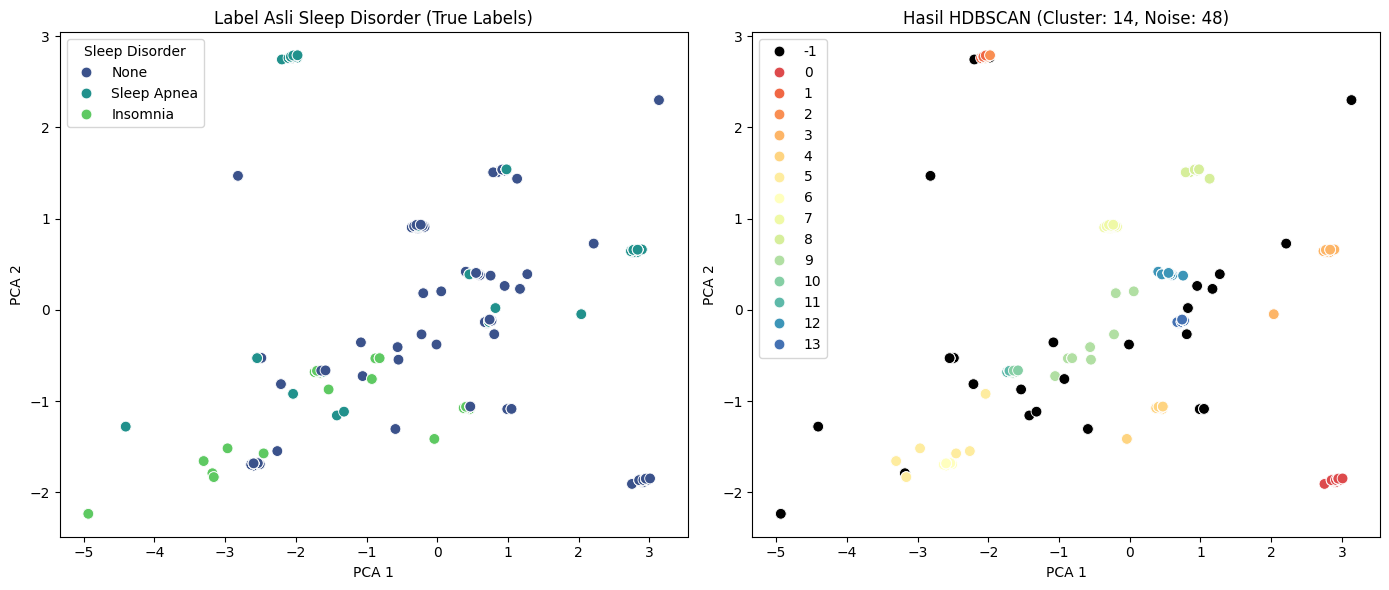

In [5]:
# Visualisasi Reduksi Dimensi dengan PCA
pca = PCA(n_components=2)
X_pca = pca.fit_transform(X)

fig, axes = plt.subplots(1, 2, figsize=(14, 6))

# Plot Label Asli
sns.scatterplot(x=X_pca[:, 0], y=X_pca[:, 1], hue=y_true, palette='viridis', ax=axes[0], s=60)
axes[0].set_title("Label Asli Sleep Disorder (True Labels)")
axes[0].set_xlabel("PCA 1")
axes[0].set_ylabel("PCA 2")

# Plot Hasil HDBSCAN
unique_labels = sorted(list(set(labels)))
palette = sns.color_palette("Spectral", len(unique_labels))
if -1 in unique_labels:
    palette[unique_labels.index(-1)] = (0.0, 0.0, 0.0)

sns.scatterplot(x=X_pca[:, 0], y=X_pca[:, 1], hue=labels, palette=palette, ax=axes[1], s=60)
axes[1].set_title(f"Hasil HDBSCAN (Cluster: {n_clusters}, Noise: {n_noise})")
axes[1].set_xlabel("PCA 1")
axes[1].set_ylabel("PCA 2")

plt.tight_layout()
plt.show()

## ANALISIS SINGKAT

Hasil clustering HDBSCAN belum sesuai dengan label asli dataset **Sleep Health and Lifestyle**.

- **Perbedaan Jumlah Kelompok.** Dataset asli memiliki 3 kategori label pada kolom *Sleep Disorder*, yaitu *None*, *Sleep Apnea*, dan *Insomnia*. Namun, algoritma HDBSCAN memecah data menjadi **14 cluster** berdasarkan kepadatan lokal pada 7 fitur numeriknya.
- **Tumpang Tindih Karakteristik Data.** Responden dengan kategori gangguan tidur yang berbeda memiliki kombinasi usia, durasi tidur, tingkat stres, dan detak jantung yang saling berdekatan atau terbagi ke dalam beberapa sub-kelompok kecil (misalnya kelompok berdasarkan usia atau profesi), sehingga HDBSCAN mendeteksinya sebagai banyak cluster terpisah.
- **Deteksi Noise.** Sebanyak **48 data** terdeteksi sebagai *noise* (label `-1`) karena memiliki kombinasi metrik kesehatan dan gaya hidup yang menyebar di luar area kepadatan utama.
- **Skor Evaluasi.** Nilai **Adjusted Rand Index (ARI)** yang dihasilkan sebesar **0.117**. Angka yang mendekati 0 ini menunjukkan bahwa pengelompokan berbasis kepadatan tanpa pengawasan (*unsupervised*) belum mampu merepresentasikan pemisahan kelas diagnosis *Sleep Disorder* yang sebenarnya.